In [1]:

%pip install pandas numpy scikit-learn matplotlib seaborn joblib flask


Note: you may need to restart the kernel to use updated packages.


In [2]:

import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns
import joblib
import flask

print("LabelLens environment is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Flask version:", flask.__version__ if hasattr(flask, "__version__") else "Installed")


LabelLens environment is ready!
Pandas version: 2.3.3
NumPy version: 2.3.5
Scikit-learn version: 1.7.2
Flask version: 3.1.2


C:\Users\Hp\AppData\Local\Temp\ipykernel_18520\1016090966.py:13: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask version:", flask.__version__ if hasattr(flask, "__version__") else "Installed")



# LabelLens — Dataset Preparation

In this stage, we will:
1. Load a classification dataset.
2. Convert it into a pandas DataFrame.
3. Inspect its rows, columns, labels, and missing values.
4. Prepare the data for detecting suspicious labels.


In [3]:

from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np

# Load the dataset
dataset = load_breast_cancer()

# Create a DataFrame containing the input features
X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# Create a Series containing the target labels
y = pd.Series(dataset.target, name="label")

# Display the first five rows
print("First five rows of the dataset:")
display(X.head())

print("\nTarget labels:")
print(dataset.target_names)


First five rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target labels:
['malignant' 'benign']


In [4]:

print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nDataset information:")
X.info()

print("\nTarget label distribution:")
print(y.value_counts().sort_index())


Number of rows: 569
Number of features: 30

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter   

In [5]:

# Count missing values in each feature
print("Missing values per feature:")
print(X.isnull().sum())

print("\nTotal missing feature values:", X.isnull().sum().sum())

# Count duplicate feature rows
print("\nDuplicate feature rows:", X.duplicated().sum())

# Check for missing target labels
print("\nMissing target labels:", y.isnull().sum())


Missing values per feature:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total missing feature values: 0

Duplicate feature rows: 0

Missing target labels: 0


In [6]:

# Combine features and labels into one DataFrame
df = X.copy()
df["label"] = y

# Display dataset dimensions
print("LabelLens dataset shape:", df.shape)

# Display the first five records
display(df.head())

# Save a copy of the original labels for evaluation
original_labels = df["label"].copy()

print("\nOriginal labels saved successfully.")


LabelLens dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Original labels saved successfully.


In [7]:

# Step 3: Introduce controlled label errors

import numpy as np
import pandas as pd

# Make sure original labels are preserved
original_labels = df["label"].copy()

# Set the percentage of labels to corrupt
noise_rate = 0.10

# Create a reproducible random number generator
rng = np.random.default_rng(42)

# Start with a copy of the original labels
noisy_labels = original_labels.copy()

# Calculate how many labels will be changed
n_corrupt = int(len(df) * noise_rate)

# Randomly select records to corrupt
corrupt_indices = rng.choice(
    df.index.to_numpy(),
    size=n_corrupt,
    replace=False
)

# Flip each selected binary label: 0 becomes 1, and 1 becomes 0
noisy_labels.loc[corrupt_indices] = (
    1 - noisy_labels.loc[corrupt_indices]
)

# Record the ground truth for our experiment
is_corrupted = (
    noisy_labels != original_labels
)

# Add the noisy labels to the working DataFrame
df["noisy_label"] = noisy_labels

print("Total records:", len(df))
print("Noise rate:", noise_rate)
print("Labels changed:", is_corrupted.sum())
print("Actual corruption percentage:",
      round(is_corrupted.mean() * 100, 2), "%")


Total records: 569
Noise rate: 0.1
Labels changed: 56
Actual corruption percentage: 9.84 %


In [8]:

# Compare original and noisy labels

comparison = pd.DataFrame({
    "original_label": original_labels,
    "noisy_label": noisy_labels,
    "is_corrupted": is_corrupted
})

print("Sample of the corrupted-label dataset:")
display(comparison.head(15))

print("\nCorruption summary:")
print(comparison["is_corrupted"].value_counts())

print("\nOriginal label distribution:")
print(original_labels.value_counts().sort_index())

print("\nNoisy label distribution:")
print(noisy_labels.value_counts().sort_index())


Sample of the corrupted-label dataset:


,original_label,noisy_label,is_corrupted
0,0,0,False
1,0,0,False
2,0,0,False
3,0,0,False
4,0,0,False
5,0,0,False
6,0,0,False
7,0,0,False
8,0,0,False
9,0,0,False



Corruption summary:
is_corrupted
False    513
True      56
Name: count, dtype: int64

Original label distribution:
label
0    212
1    357
Name: count, dtype: int64

Noisy label distribution:
label
0    234
1    335
Name: count, dtype: int64


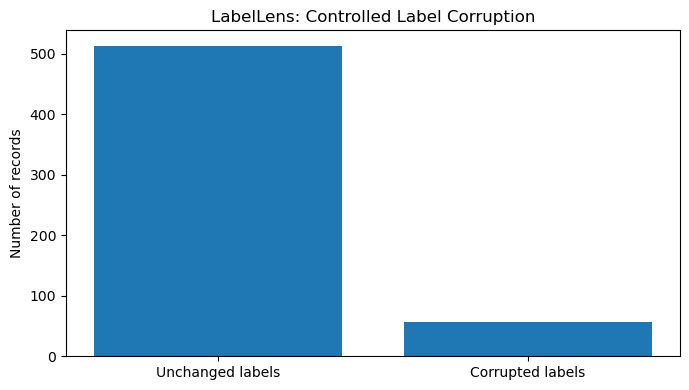

In [9]:

import matplotlib.pyplot as plt

counts = [
    int((~is_corrupted).sum()),
    int(is_corrupted.sum())
]

plt.figure(figsize=(7, 4))
plt.bar(
    ["Unchanged labels", "Corrupted labels"],
    counts
)

plt.title("LabelLens: Controlled Label Corruption")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()


In [10]:

# Verify that only the intended labels were changed

assert original_labels.equals(y), (
    "The original labels have unexpectedly changed!"
)

assert (noisy_labels != original_labels).equals(
    is_corrupted
), "The corruption tracking mask is incorrect!"

assert is_corrupted.sum() == int(len(df) * noise_rate), (
    "Unexpected number of corrupted labels!"
)

print("All checks passed!")
print("Original labels are preserved.")
print("Corrupted records are tracked correctly.")
print("LabelLens ground truth is ready.")


All checks passed!
Original labels are preserved.
Corrupted records are tracked correctly.
LabelLens ground truth is ready.


In [11]:

# Step 4.2: Prepare features and noisy training labels

X_features = X.copy()
y_noisy = noisy_labels.copy()

print("Feature shape:", X_features.shape)
print("Training label shape:", y_noisy.shape)
print("Number of features:", X_features.shape[1])
print("Number of training labels:", len(y_noisy))


Feature shape: (569, 30)
Training label shape: (569,)
Number of features: 30
Number of training labels: 569


In [12]:

# Step 4.3: Generate out-of-fold predictions

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model 1: Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

lr_predictions = cross_val_predict(
    lr_model,
    X_features,
    y_noisy,
    cv=cv,
    method="predict"
)

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_predictions = cross_val_predict(
    rf_model,
    X_features,
    y_noisy,
    cv=cv,
    method="predict"
)

print("Cross-validation completed!")
print("Logistic Regression predictions:", len(lr_predictions))
print("Random Forest predictions:", len(rf_predictions))


Cross-validation completed!
Logistic Regression predictions: 569
Random Forest predictions: 569


In [13]:

# Step 4.4: Calculate disagreement scores

lr_disagreement = (
    lr_predictions != y_noisy.to_numpy()
).astype(int)

rf_disagreement = (
    rf_predictions != y_noisy.to_numpy()
).astype(int)

# Average the two disagreement signals
disagreement_score = (
    lr_disagreement + rf_disagreement
) / 2

# Store the results
results = X_features.copy()
results["supplied_label"] = y_noisy.to_numpy()
results["lr_prediction"] = lr_predictions
results["rf_prediction"] = rf_predictions
results["disagreement_score"] = disagreement_score

# Sort records from most suspicious to least suspicious
results = results.sort_values(
    by="disagreement_score",
    ascending=False
)

print("Highest-scoring suspicious records:")
display(
    results[
        [
            "supplied_label",
            "lr_prediction",
            "rf_prediction",
            "disagreement_score"
        ]
    ].head(15)
)


Highest-scoring suspicious records:


,supplied_label,lr_prediction,rf_prediction,disagreement_score
415,0,1,1,1.0
217,0,1,1,1.0
215,0,1,1,1.0
456,0,1,1,1.0
73,0,1,1,1.0
512,1,0,0,1.0
264,1,0,0,1.0
267,0,1,1,1.0
349,0,1,1,1.0
472,0,1,1,1.0


In [14]:

# Step 4.5: Evaluate the baseline detector

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# A simple baseline: flag records where both models disagree
predicted_suspicious = (
    disagreement_score == 1.0
).astype(int)

# Ground truth: 1 means deliberately corrupted
true_corrupted = is_corrupted.to_numpy().astype(int)

print("Precision:",
      round(precision_score(
          true_corrupted, predicted_suspicious,
          zero_division=0
      ), 3))

print("Recall:",
      round(recall_score(
          true_corrupted, predicted_suspicious,
          zero_division=0
      ), 3))

print("F1-score:",
      round(f1_score(
          true_corrupted, predicted_suspicious,
          zero_division=0
      ), 3))

print("\nConfusion matrix:")
print(confusion_matrix(
    true_corrupted, predicted_suspicious
))

print("\nClassification report:")
print(classification_report(
    true_corrupted,
    predicted_suspicious,
    target_names=["Unchanged", "Corrupted"],
    zero_division=0
))


Precision: 0.839
Recall: 0.929
F1-score: 0.881

Confusion matrix:
[[503  10]
 [  4  52]]

Classification report:
              precision    recall  f1-score   support

   Unchanged       0.99      0.98      0.99       513
   Corrupted       0.84      0.93      0.88        56

    accuracy                           0.98       569
   macro avg       0.92      0.95      0.93       569
weighted avg       0.98      0.98      0.98       569



In [15]:

# Step 5.2: Prepare features for neighborhood analysis

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

scaler_neighbors = StandardScaler()

X_scaled = scaler_neighbors.fit_transform(X_features)

print("Scaled feature shape:", X_scaled.shape)
print("Features are ready for neighborhood analysis.")


Scaled feature shape: (569, 30)
Features are ready for neighborhood analysis.


In [16]:

# Step 5.3: Find nearest neighbors

k = 10

neighbor_model = NearestNeighbors(
    n_neighbors=k + 1,
    metric="euclidean"
)

neighbor_model.fit(X_scaled)

distances, neighbor_indices = neighbor_model.kneighbors(
    X_scaled
)

# Remove each record's own index from its neighbor list
clean_neighbor_indices = []

for i, indices in enumerate(neighbor_indices):
    other_indices = indices[indices != i]
    clean_neighbor_indices.append(other_indices[:k])

clean_neighbor_indices = np.array(clean_neighbor_indices)

print("Number of records:", len(clean_neighbor_indices))
print("Neighbors per record:", clean_neighbor_indices.shape[1])
print("Self-neighbors excluded.")


Number of records: 569
Neighbors per record: 10
Self-neighbors excluded.


In [17]:

# Step 5.4: Calculate neighborhood disagreement

y_noisy_array = y_noisy.to_numpy()

neighborhood_scores = []

for i, neighbor_ids in enumerate(clean_neighbor_indices):

    # Get labels of the 10 nearest neighbors
    neighbor_labels = y_noisy_array[neighbor_ids]

    # Count the neighbors whose labels differ
    disagreements = np.sum(
        neighbor_labels != y_noisy_array[i]
    )

    # Calculate the proportion of disagreement
    score = disagreements / k

    neighborhood_scores.append(score)

neighborhood_scores = np.array(neighborhood_scores)

# Store scores using the original DataFrame index
neighborhood_score = pd.Series(
    neighborhood_scores,
    index=X_features.index,
    name="neighborhood_score"
)

results["neighborhood_score"] = neighborhood_score

print("Neighborhood scores calculated!")
print("\nScore distribution:")
print(neighborhood_score.describe())


Neighborhood scores calculated!

Score distribution:
count    569.000000
mean       0.218453
std        0.255972
min        0.000000
25%        0.100000
50%        0.100000
75%        0.200000
max        1.000000
Name: neighborhood_score, dtype: float64


In [18]:

# Step 5.5: Display records with the highest neighborhood scores

display(
    results.sort_values(
        by="neighborhood_score",
        ascending=False
    )[
        [
            "supplied_label",
            "lr_prediction",
            "rf_prediction",
            "disagreement_score",
            "neighborhood_score"
        ]
    ].head(15)
)


,supplied_label,lr_prediction,rf_prediction,disagreement_score,neighborhood_score
540,0,1,1,1.0,1.0
389,1,0,0,1.0,1.0
249,0,1,1,1.0,1.0
387,0,1,1,1.0,1.0
380,0,1,1,1.0,1.0
245,0,1,1,1.0,1.0
224,0,1,1,1.0,1.0
428,0,1,1,1.0,1.0
272,1,0,0,1.0,1.0
497,0,1,1,1.0,1.0


In [19]:

# Step 5.6: Evaluate neighborhood disagreement

from sklearn.metrics import precision_score, recall_score, f1_score

# Flag records when at least half their neighbors disagree
neighborhood_predicted = (
    neighborhood_scores >= 0.5
).astype(int)

true_corrupted = is_corrupted.to_numpy().astype(int)

print("Neighborhood Detector")
print("---------------------")

print(
    "Precision:",
    round(precision_score(
        true_corrupted,
        neighborhood_predicted,
        zero_division=0
    ), 3)
)

print(
    "Recall:",
    round(recall_score(
        true_corrupted,
        neighborhood_predicted,
        zero_division=0
    ), 3)
)

print(
    "F1-score:",
    round(f1_score(
        true_corrupted,
        neighborhood_predicted,
        zero_division=0
    ), 3)
)


Neighborhood Detector
---------------------
Precision: 0.701
Recall: 0.964
F1-score: 0.812


In [20]:

# Step 5.7: Compare both baseline detectors

comparison_results = pd.DataFrame({
    "Method": [
        "Model Disagreement",
        "Neighborhood Disagreement"
    ],
    "Precision": [
        precision_score(
            true_corrupted,
            predicted_suspicious,
            zero_division=0
        ),
        precision_score(
            true_corrupted,
            neighborhood_predicted,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            true_corrupted,
            predicted_suspicious,
            zero_division=0
        ),
        recall_score(
            true_corrupted,
            neighborhood_predicted,
            zero_division=0
        )
    ],
    "F1-score": [
        f1_score(
            true_corrupted,
            predicted_suspicious,
            zero_division=0
        ),
        f1_score(
            true_corrupted,
            neighborhood_predicted,
            zero_division=0
        )
    ]
})

display(
    comparison_results.round(3)
)


,Method,Precision,Recall,F1-score
0,Model Disagreement,0.839,0.929,0.881
1,Neighborhood Disagreement,0.701,0.964,0.812


In [21]:

# Step 6.2: Combine both detection signals

# Convert both scores to NumPy arrays in original row order
model_scores = (
    lr_disagreement + rf_disagreement
) / 2

combined_scores = (
    0.5 * model_scores
    + 0.5 * neighborhood_scores
)

# Save the combined scores against the original row indices
combined_score = pd.Series(
    combined_scores,
    index=X_features.index,
    name="combined_score"
)

# Add the scores to our results table
results["combined_score"] = combined_score

print("Combined LabelLens scores created!")
print("\nScore summary:")
print(combined_score.describe())


Combined LabelLens scores created!

Score summary:
count    569.000000
mean       0.176011
std        0.279241
min        0.000000
25%        0.050000
50%        0.050000
75%        0.150000
max        1.000000
Name: combined_score, dtype: float64


In [22]:

# Step 6.3: Rank records by combined suspiciousness

ranked_results = results.sort_values(
    by="combined_score",
    ascending=False
)

columns_to_display = [
    "supplied_label",
    "lr_prediction",
    "rf_prediction",
    "disagreement_score",
    "neighborhood_score",
    "combined_score"
]

display(ranked_results[columns_to_display].head(20))


,supplied_label,lr_prediction,rf_prediction,disagreement_score,neighborhood_score,combined_score
540,0,1,1,1.0,1.0,1.00
389,1,0,0,1.0,1.0,1.00
249,0,1,1,1.0,1.0,1.00
387,0,1,1,1.0,1.0,1.00
380,0,1,1,1.0,1.0,1.00
245,0,1,1,1.0,1.0,1.00
224,0,1,1,1.0,1.0,1.00
272,1,0,0,1.0,1.0,1.00
428,0,1,1,1.0,1.0,1.00
497,0,1,1,1.0,1.0,1.00


In [23]:

# Step 6.4: Flag records using a fixed threshold

threshold = 0.5

combined_predicted = (
    combined_scores >= threshold
).astype(int)

# Store the flags in the results table
results["is_suspicious"] = combined_predicted

print("Threshold:", threshold)
print(
    "Records flagged:",
    int(combined_predicted.sum())
)
print(
    "Percentage flagged:",
    round(combined_predicted.mean() * 100, 2),
    "%"
)

print("\nFlagged record examples:")
display(
    results.loc[
        results["is_suspicious"] == 1,
        columns_to_display
    ].head(10)
)


Threshold: 0.5
Records flagged: 73
Percentage flagged: 12.83 %

Flagged record examples:


,supplied_label,lr_prediction,rf_prediction,disagreement_score,neighborhood_score,combined_score
226,0,1,1,1.0,0.9,0.95
91,1,0,0,1.0,0.3,0.65
497,0,1,1,1.0,1.0,1.00
249,0,1,1,1.0,1.0,1.00
44,1,0,0,1.0,0.7,0.85
380,0,1,1,1.0,1.0,1.00
24,1,0,0,1.0,0.9,0.95
554,0,1,1,1.0,0.9,0.95
198,1,0,0,1.0,0.8,0.90
542,0,1,1,1.0,0.6,0.80


In [24]:

# Step 6.5: Evaluate and compare all three methods

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Ground truth is used ONLY for evaluation
true_corrupted = (
    is_corrupted.to_numpy().astype(int)
)

# Three detection methods
method_predictions = {
    "Model Disagreement": predicted_suspicious,
    "Neighborhood Disagreement": neighborhood_predicted,
    "Combined LabelLens": combined_predicted
}

comparison_rows = []

for method_name, predictions in method_predictions.items():

    comparison_rows.append({
        "Method": method_name,
        "Precision": precision_score(
            true_corrupted,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            true_corrupted,
            predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            true_corrupted,
            predictions,
            zero_division=0
        ),
        "Records Flagged": int(predictions.sum())
    })

evaluation_table = pd.DataFrame(comparison_rows)

display(evaluation_table.round(3))


,Method,Precision,Recall,F1-score,Records Flagged
0,Model Disagreement,0.839,0.929,0.881,62
1,Neighborhood Disagreement,0.701,0.964,0.812,77
2,Combined LabelLens,0.753,0.982,0.853,73


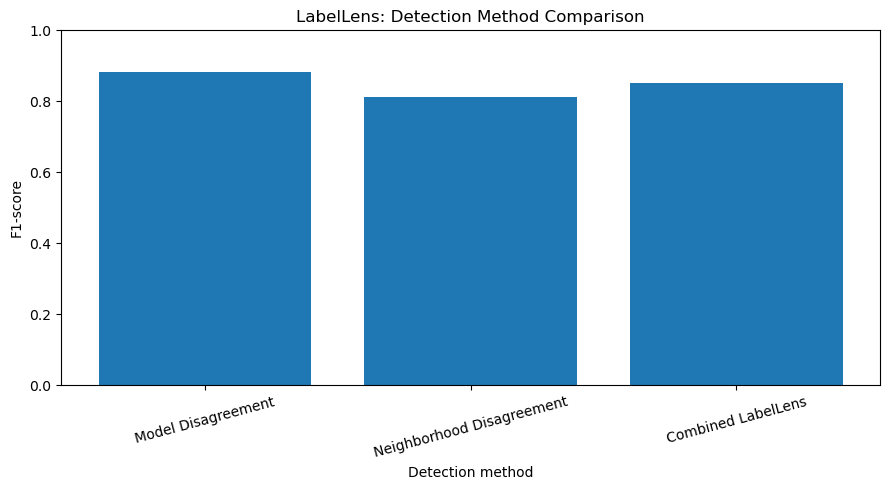

In [25]:

# Step 6.6: Plot the F1-score comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    evaluation_table["Method"],
    evaluation_table["F1-score"]
)

plt.title("LabelLens: Detection Method Comparison")
plt.ylabel("F1-score")
plt.xlabel("Detection method")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



# Step 7 — LabelLens Research Experiments

We will evaluate our label-error detection methods under different
label-corruption rates and random seeds.

The original labels will be used only to generate controlled noise
and evaluate detection performance.


In [26]:

# Step 7.2: Define the experiment function

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import precision_score, recall_score, f1_score

def run_labellens_experiment(noise_rate, seed):

    # 1. Start with the original, unchanged labels
    clean_y = original_labels.to_numpy()

    # 2. Create a reproducible corrupted version
    rng = np.random.default_rng(seed)
    noisy_y = clean_y.copy()

    n_corrupt = int(len(clean_y) * noise_rate)

    corrupt_indices = rng.choice(
        len(clean_y),
        size=n_corrupt,
        replace=False
    )

    noisy_y[corrupt_indices] = 1 - noisy_y[corrupt_indices]

    # Ground truth for evaluation only
    corrupted_mask = (noisy_y != clean_y).astype(int)

    # 3. Generate out-of-fold predictions
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    lr_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=seed)
    )

    rf_model = RandomForestClassifier(
        n_estimators=50,
        random_state=seed,
        n_jobs=-1
    )

    lr_pred = cross_val_predict(
        lr_model, X_features, noisy_y, cv=cv
    )

    rf_pred = cross_val_predict(
        rf_model, X_features, noisy_y, cv=cv
    )

    # 4. Calculate model disagreement
    model_score = (
        (lr_pred != noisy_y).astype(float)
        + (rf_pred != noisy_y).astype(float)
    ) / 2

    # 5. Calculate neighborhood disagreement
    # Use standardized features and exclude each record itself
    scaler = StandardScaler()
    X_scaled_exp = scaler.fit_transform(X_features)

    k = 10

    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric="euclidean"
    )

    nn.fit(X_scaled_exp)
    _, neighbor_indices = nn.kneighbors(X_scaled_exp)

    neighbor_scores = []

    for i, indices in enumerate(neighbor_indices):
        other_indices = indices[indices != i][:k]

        score = np.mean(
            noisy_y[other_indices] != noisy_y[i]
        )

        neighbor_scores.append(score)

    neighbor_score = np.array(neighbor_scores)

    # 6. Combine both scores
    combined_score = (
        0.5 * model_score + 0.5 * neighbor_score
    )

    # 7. Evaluate using the same fixed threshold
    predictions = {
        "Model Disagreement": (
            model_score == 1.0
        ).astype(int),

        "Neighborhood Disagreement": (
            neighbor_score >= 0.5
        ).astype(int),

        "Combined LabelLens": (
            combined_score >= 0.5
        ).astype(int)
    }

    # 8. Return evaluation results
    rows = []

    for method, pred in predictions.items():
        rows.append({
            "Noise Rate": noise_rate,
            "Seed": seed,
            "Method": method,
            "Precision": precision_score(
                corrupted_mask, pred, zero_division=0
            ),
            "Recall": recall_score(
                corrupted_mask, pred, zero_division=0
            ),
            "F1-score": f1_score(
                corrupted_mask, pred, zero_division=0
            ),
            "Flagged %": pred.mean() * 100
        })

    return rows

print("LabelLens experiment function is ready!")


LabelLens experiment function is ready!


In [27]:

# Step 7.3: Run experiments with multiple noise rates and seeds

noise_rates = [0.05, 0.10, 0.20, 0.30]
random_seeds = [42, 21, 7]

all_results = []

for rate in noise_rates:
    for seed in random_seeds:

        experiment_results = run_labellens_experiment(
            noise_rate=rate,
            seed=seed
        )

        all_results.extend(experiment_results)

        print(
            f"Completed: noise={rate:.0%}, seed={seed}"
        )

experiment_df = pd.DataFrame(all_results)

print("\nAll experiments completed!")
print("Total experiment results:", len(experiment_df))


Completed: noise=5%, seed=42
Completed: noise=5%, seed=21
Completed: noise=5%, seed=7
Completed: noise=10%, seed=42
Completed: noise=10%, seed=21
Completed: noise=10%, seed=7
Completed: noise=20%, seed=42
Completed: noise=20%, seed=21
Completed: noise=20%, seed=7
Completed: noise=30%, seed=42
Completed: noise=30%, seed=21
Completed: noise=30%, seed=7

All experiments completed!
Total experiment results: 36


In [28]:

# Step 7.4: Average performance across random seeds

summary = (
    experiment_df
    .groupby(["Noise Rate", "Method"])[
        ["Precision", "Recall", "F1-score", "Flagged %"]
    ]
    .mean()
    .reset_index()
)

display(summary.round(3))


,Noise Rate,Method,Precision,Recall,F1-score,Flagged %
0,0.05,Combined LabelLens,0.614,0.964,0.750,7.733
1,0.05,Model Disagreement,0.747,0.952,0.837,6.268
2,0.05,Neighborhood Disagreement,0.554,0.976,0.707,8.670
3,0.10,Combined LabelLens,0.728,0.982,0.836,13.298
4,0.10,Model Disagreement,0.834,0.929,0.879,10.955
5,0.10,Neighborhood Disagreement,0.694,0.982,0.813,13.943
6,0.20,Combined LabelLens,0.816,0.968,0.885,23.550
7,0.20,Model Disagreement,0.907,0.888,0.897,19.449
8,0.20,Neighborhood Disagreement,0.699,0.965,0.810,27.417
9,0.30,Combined LabelLens,0.794,0.931,0.857,35.091


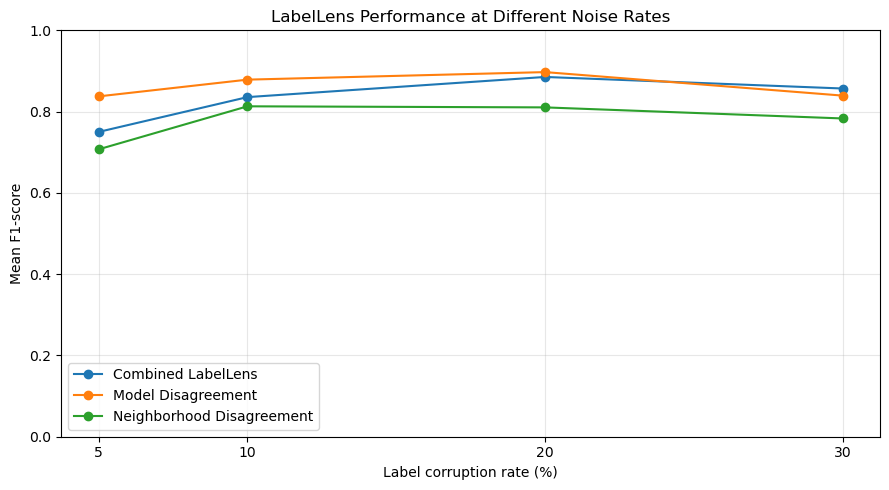

In [29]:

# Step 7.5: Plot F1-score against the corruption rate

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for method in summary["Method"].unique():

    method_data = summary[
        summary["Method"] == method
    ].sort_values("Noise Rate")

    plt.plot(
        method_data["Noise Rate"] * 100,
        method_data["F1-score"],
        marker="o",
        label=method
    )

plt.title("LabelLens Performance at Different Noise Rates")
plt.xlabel("Label corruption rate (%)")
plt.ylabel("Mean F1-score")
plt.xticks([5, 10, 20, 30])
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

# Step 7.6: Save the experiment results

experiment_df.to_csv(
    "labellens_experiment_results.csv",
    index=False
)

summary.to_csv(
    "labellens_experiment_summary.csv",
    index=False
)

print("Research results saved successfully!")
print("1. labellens_experiment_results.csv")
print("2. labellens_experiment_summary.csv")


Research results saved successfully!
1. labellens_experiment_results.csv
2. labellens_experiment_summary.csv


In [31]:

# Step 8.1: Create the human-review queue

review_queue = results.copy()

# Preserve the original row index as a record ID
review_queue.index.name = "record_id"
review_queue = review_queue.reset_index()

# Add columns for human decisions
review_queue["review_status"] = "Needs review"
review_queue["review_notes"] = ""

# Show the most suspicious records first
review_queue = review_queue.sort_values(
    by="combined_score",
    ascending=False
).reset_index(drop=True)

print("Human-review queue created!")
print("Total records available:", len(review_queue))

display(
    review_queue[
        [
            "record_id",
            "supplied_label",
            "disagreement_score",
            "neighborhood_score",
            "combined_score",
            "review_status"
        ]
    ].head(20)
)


Human-review queue created!
Total records available: 569


,record_id,supplied_label,disagreement_score,neighborhood_score,combined_score,review_status
0,540,0,1.0,1.0,1.00,Needs review
1,389,1,1.0,1.0,1.00,Needs review
2,249,0,1.0,1.0,1.00,Needs review
3,387,0,1.0,1.0,1.00,Needs review
4,380,0,1.0,1.0,1.00,Needs review
5,245,0,1.0,1.0,1.00,Needs review
6,224,0,1.0,1.0,1.00,Needs review
7,272,1,1.0,1.0,1.00,Needs review
8,428,0,1.0,1.0,1.00,Needs review
9,497,0,1.0,1.0,1.00,Needs review


In [32]:

# Step 8.2: Define the record-review function

def review_record(record_id, decision, note=""):

    valid_decisions = [
        "Confirmed incorrect",
        "Valid label",
        "Needs further review"
    ]

    if decision not in valid_decisions:
        raise ValueError(
            f"Decision must be one of: {valid_decisions}"
        )

    matching_rows = review_queue.index[
        review_queue["record_id"] == record_id
    ]

    if len(matching_rows) == 0:
        raise ValueError("Record ID not found.")

    row_position = matching_rows[0]

    review_queue.loc[
        row_position, "review_status"
    ] = decision

    review_queue.loc[
        row_position, "review_notes"
    ] = note

    print(f"Record {record_id} updated successfully.")
    print("Decision:", decision)


In [33]:

# Test the review function

example_record_id = int(review_queue.iloc[0]["record_id"])

review_record(
    record_id=example_record_id,
    decision="Needs further review",
    note="Example test of the review function."
)


Record 540 updated successfully.
Decision: Needs further review


In [34]:

display(
    review_queue.loc[
        review_queue["record_id"] == example_record_id,
        ["record_id", "review_status", "review_notes"]
    ]
)


,record_id,review_status,review_notes
0,540,Needs further review,Example test of the review function.


In [35]:

# Step 8.3: Demonstrate a review decision

example_record_id = int(
    review_queue.iloc[0]["record_id"]
)

review_record(
    record_id=example_record_id,
    decision="Needs further review",
    note="Example review only; requires manual verification."
)

display(
    review_queue.loc[
        review_queue["record_id"] == example_record_id,
        [
            "record_id",
            "supplied_label",
            "combined_score",
            "review_status",
            "review_notes"
        ]
    ]
)


Record 540 updated successfully.
Decision: Needs further review


,record_id,supplied_label,combined_score,review_status,review_notes
0,540,0,1.0,Needs further review,Example review only; requires manual verificat...


In [36]:
review_record(
    record_id=123,
    decision="Confirmed incorrect",
    note="Verified against the trusted source."
)

Record 123 updated successfully.
Decision: Confirmed incorrect


In [37]:

# Step 8.4: View review progress

print("Review status summary:")

display(
    review_queue["review_status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Number of records")
)

print("\nRecords reviewed or flagged for follow-up:")

display(
    review_queue[
        review_queue["review_status"] != "Needs review"
    ][
        [
            "record_id",
            "supplied_label",
            "combined_score",
            "review_status",
            "review_notes"
        ]
    ]
)


Review status summary:


,Status,Number of records
0,Needs review,567
1,Needs further review,1
2,Confirmed incorrect,1



Records reviewed or flagged for follow-up:


,record_id,supplied_label,combined_score,review_status,review_notes
0,540,0,1.0,Needs further review,Example review only; requires manual verificat...
15,123,0,1.0,Confirmed incorrect,Verified against the trusted source.


In [38]:

# Step 8.5: Save the review queue

review_queue.to_csv(
    "labellens_review_queue.csv",
    index=False
)

print("Review queue saved successfully!")
print("File: labellens_review_queue.csv")


Review queue saved successfully!
File: labellens_review_queue.csv



# Step 9 — Evaluate the Impact of Label Correction

We will compare model performance using clean training labels,
corrupted training labels, and LabelLens-assisted corrections.

The test set will remain clean and untouched throughout the experiment.


In [39]:

# Step 9.1: Split the original dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train_clean, y_test = train_test_split(
    X_features,
    original_labels,
    test_size=0.20,
    random_state=42,
    stratify=original_labels
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training labels are clean initially.")
print("Test labels remain unchanged.")


Training records: 455
Testing records: 114
Training labels are clean initially.
Test labels remain unchanged.


In [40]:

# Step 9.2: Corrupt training labels only

rng = np.random.default_rng(42)

y_train_noisy = y_train_clean.to_numpy().copy()

n_corrupt_train = int(len(y_train_noisy) * 0.10)

corrupt_train_indices = rng.choice(
    len(y_train_noisy),
    size=n_corrupt_train,
    replace=False
)

y_train_noisy[corrupt_train_indices] = (
    1 - y_train_noisy[corrupt_train_indices]
)

print("Training records:", len(y_train_noisy))
print("Labels deliberately changed:", n_corrupt_train)
print("Test records corrupted: 0")


Training records: 455
Labels deliberately changed: 45
Test records corrupted: 0


In [41]:

# Step 9.3: Detect suspicious labels in training data

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_detector = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

rf_detector = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Out-of-fold predictions: each row is predicted by a model
# that was not trained on that row.
lr_oof = cross_val_predict(
    lr_detector, X_train, y_train_noisy, cv=cv
)

rf_oof = cross_val_predict(
    rf_detector, X_train, y_train_noisy, cv=cv
)

# Model disagreement with supplied labels
model_score_train = (
    (lr_oof != y_train_noisy).astype(float)
    + (rf_oof != y_train_noisy).astype(float)
) / 2

# Scale training features for neighborhood analysis
train_scaler = StandardScaler()
X_train_scaled = train_scaler.fit_transform(X_train)

k = 10

nn_train = NearestNeighbors(
    n_neighbors=k + 1,
    metric="euclidean"
)

nn_train.fit(X_train_scaled)

_, neighbor_indices_train = nn_train.kneighbors(
    X_train_scaled
)

neighbor_score_train = []

for i, indices in enumerate(neighbor_indices_train):
    other_indices = indices[indices != i][:k]

    score = np.mean(
        y_train_noisy[other_indices] != y_train_noisy[i]
    )

    neighbor_score_train.append(score)

neighbor_score_train = np.array(neighbor_score_train)

# Combined suspiciousness score
combined_score_train = (
    0.5 * model_score_train
    + 0.5 * neighbor_score_train
)

threshold = 0.5

suspect_mask = combined_score_train >= threshold

print("Suspicious training records:", int(suspect_mask.sum()))
print(
    "Percentage flagged:",
    round(suspect_mask.mean() * 100, 2),
    "%"
)


Suspicious training records: 59
Percentage flagged: 12.97 %


In [42]:

# Step 9.4: Create LabelLens-assisted corrected labels

y_train_corrected = y_train_noisy.copy()

# Identify records where:
# 1. LabelLens flagged the record
# 2. Both models agree with each other
# 3. Their prediction differs from the supplied label

model_consensus = (lr_oof == rf_oof)

correction_mask = (
    suspect_mask
    & model_consensus
    & (lr_oof != y_train_noisy)
)

# Replace selected suspicious labels with the agreed prediction
y_train_corrected[correction_mask] = lr_oof[correction_mask]

print("Corrected training labels created!")
print("Records flagged:", int(suspect_mask.sum()))
print("Records corrected:", int(correction_mask.sum()))


Corrected training labels created!
Records flagged: 59
Records corrected: 51


In [43]:

# Step 9.5: Compare downstream model performance

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_training_labels(label_array, scenario_name):

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, label_array)
    predictions = model.predict(X_test)

    return {
        "Scenario": scenario_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }


comparison = pd.DataFrame([
    evaluate_training_labels(
        y_train_clean.to_numpy(),
        "Clean training labels"
    ),
    evaluate_training_labels(
        y_train_noisy,
        "Corrupted training labels"
    ),
    evaluate_training_labels(
        y_train_corrected,
        "LabelLens-assisted corrections"
    )
])

display(comparison.round(3))


,Scenario,Accuracy,Precision,Recall,F1-score
0,Clean training labels,0.956,0.959,0.972,0.966
1,Corrupted training labels,0.947,0.971,0.944,0.958
2,LabelLens-assisted corrections,0.956,0.959,0.972,0.966


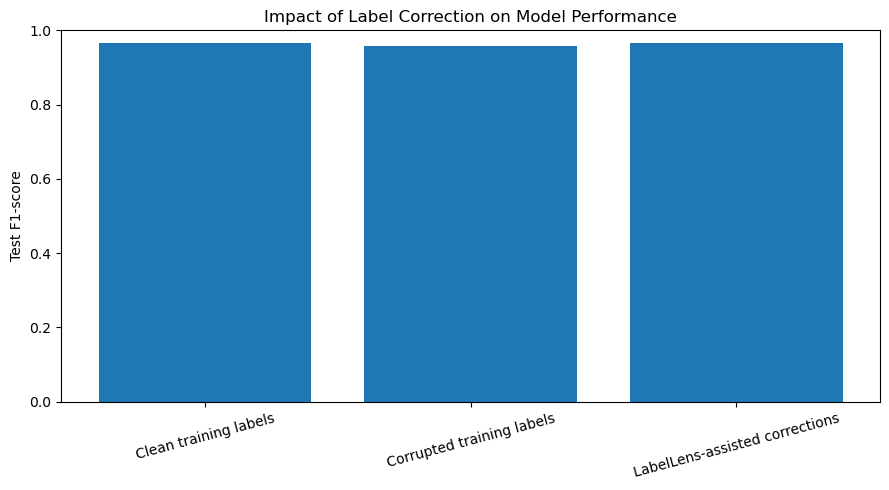

In [44]:

# Step 9.6: Plot F1-score for each training scenario

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Scenario"],
    comparison["F1-score"]
)

plt.title("Impact of Label Correction on Model Performance")
plt.ylabel("Test F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [45]:

from pathlib import Path

# Create folders for our Flask application
Path("LabelLens/templates").mkdir(parents=True, exist_ok=True)
Path("LabelLens/static").mkdir(parents=True, exist_ok=True)

print("Project folders created successfully!")
print("LabelLens/")
print("    app.py")
print("    templates/")
print("        index.html")
print("    static/")
print("        style.css")


Project folders created successfully!
LabelLens/
    app.py
    templates/
        index.html
    static/
        style.css


In [46]:

%%writefile LabelLens/app.py

from io import BytesIO

import numpy as np
import pandas as pd

from flask import (
    Flask, render_template, request, redirect,
    url_for, flash, send_file
)

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors

app = Flask(__name__)
app.secret_key = "replace-this-with-a-random-secret"
app.config["MAX_CONTENT_LENGTH"] = 5 * 1024 * 1024

# Local prototype: results stay in memory while the server runs.
results_df = None
feature_columns = []
target_name = None


def analyze_dataset(data, target):
    if target not in data.columns:
        raise ValueError("Select a valid target-label column.")

    if len(data) < 25:
        raise ValueError("Upload at least 25 data records.")

    if data[target].isna().any():
        raise ValueError("The target column contains missing values.")

    X = data.drop(columns=[target])
    y_original = data[target]

    if X.shape[1] == 0:
        raise ValueError("The dataset needs at least one feature.")

    if not all(pd.api.types.is_numeric_dtype(X[c]) for c in X.columns):
        raise ValueError(
            "All feature columns must be numeric in this version."
        )

    if X.isna().any().any():
        raise ValueError("Feature columns contain missing values.")

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("Features must contain finite numeric values.")

    encoder = LabelEncoder()
    y = encoder.fit_transform(y_original)

    if len(encoder.classes_) != 2:
        raise ValueError(
            "This version supports binary classification only."
        )

    class_counts = np.bincount(y)
    if class_counts.min() < 5:
        raise ValueError(
            "Each class needs at least 5 records for 5-fold validation."
        )

    cv = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=42
    )

    lr = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    )

    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    # Out-of-fold predictions: each row is predicted by a model
    # that was not trained on that row.
    lr_pred = cross_val_predict(lr, X, y, cv=cv)
    rf_pred = cross_val_predict(rf, X, y, cv=cv)

    model_score = (
        (lr_pred != y).astype(float)
        + (rf_pred != y).astype(float)
    ) / 2

    # Standardize features before computing nearest neighbors.
    X_scaled = StandardScaler().fit_transform(X)

    k = min(10, len(data) - 1)

    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(X_scaled)
    _, indices = nn.kneighbors(X_scaled)

    neighborhood_scores = []

    for i, neighbor_ids in enumerate(indices):
        other_ids = neighbor_ids[neighbor_ids != i][:k]
        score = np.mean(y[other_ids] != y[i])
        neighborhood_scores.append(score)

    neighborhood_score = np.array(neighborhood_scores)

    combined_score = (
        0.5 * model_score + 0.5 * neighborhood_score
    )

    # Store original labels for display, not encoded labels.
    result = pd.DataFrame({
        "record_id": np.arange(len(data)),
        "supplied_label": y_original.to_numpy(),
        "lr_prediction": encoder.inverse_transform(lr_pred),
        "rf_prediction": encoder.inverse_transform(rf_pred),
        "disagreement_score": model_score,
        "neighborhood_score": neighborhood_score,
        "combined_score": combined_score,
        "review_status": "Needs review",
        "review_notes": ""
    })

    # Keep original feature values available in the exported report.
    for column in X.columns:
        result[column] = X[column].to_numpy()

    return result


@app.route("/", methods=["GET", "POST"])
def index():
    global results_df, feature_columns, target_name

    if request.method == "POST":
        uploaded_file = request.files.get("file")
        target = request.form.get("target", "").strip()

        if not uploaded_file or not uploaded_file.filename:
            flash("Please select a CSV file.")
            return redirect(url_for("index"))

        if not uploaded_file.filename.lower().endswith(".csv"):
            flash("Please upload a CSV file.")
            return redirect(url_for("index"))

        try:
            data = pd.read_csv(uploaded_file)

            if data.empty:
                raise ValueError("The uploaded CSV is empty.")

            results_df = analyze_dataset(data, target)
            feature_columns = [
                c for c in data.columns if c != target
            ]
            target_name = target

            flash(
                f"Analysis complete: {len(results_df)} records analyzed."
            )

        except Exception as exc:
            flash(f"Could not analyze the dataset: {exc}")

        return redirect(url_for("index"))

    preview = []
    total_records = 0
    flagged_count = 0

    if results_df is not None:
        total_records = len(results_df)
        flagged_count = int(
            (results_df["combined_score"] >= 0.5).sum()
        )

        preview = (
            results_df
            .sort_values("combined_score", ascending=False)
            .head(100)
            .to_dict(orient="records")
        )

    return render_template(
        "index.html",
        preview=preview,
        total_records=total_records,
        flagged_count=flagged_count,
        feature_columns=feature_columns,
        target_name=target_name
    )


@app.route("/review", methods=["POST"])
def review():
    global results_df

    if results_df is None:
        flash("Upload a dataset before reviewing records.")
        return redirect(url_for("index"))

    try:
        record_id = int(request.form["record_id"])
        decision = request.form["review_status"]
        note = request.form.get("review_notes", "").strip()

        valid_decisions = {
            "Confirmed incorrect",
            "Valid label",
            "Needs review"
        }

        if decision not in valid_decisions:
            raise ValueError("Invalid review decision.")

        matching = results_df.index[
            results_df["record_id"] == record_id
        ]

        if len(matching) == 0:
            raise ValueError("Record not found.")

        idx = matching[0]
        results_df.at[idx, "review_status"] = decision
        results_df.at[idx, "review_notes"] = note

        flash(f"Review saved for record {record_id}.")

    except (ValueError, KeyError):
        flash("Could not save the review. Check the record and decision.")

    return redirect(url_for("index"))


@app.route("/export")
def export():
    if results_df is None:
        flash("Analyze a dataset before exporting.")
        return redirect(url_for("index"))

    output = BytesIO()
    output.write(results_df.to_csv(index=False).encode("utf-8"))
    output.seek(0)

    return send_file(
        output,
        mimetype="text/csv",
        as_attachment=True,
        download_name="labellens_review_results.csv"
    )


if __name__ == "__main__":
    app.run(host="127.0.0.1", port=5000, debug=False)


Overwriting LabelLens/app.py


In [47]:

%%writefile LabelLens/templates/index.html

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>LabelLens | Data Quality Audit</title>
    <link rel="stylesheet" href="{{ url_for('static', filename='style.css') }}">
</head>
<body>
    <header class="topbar">
        <a class="brand" href="/">Label<span>Lens</span></a>
        <span class="tagline">ML-powered data quality review</span>
    </header>

    <main class="container">
        <section class="hero">
            <p class="eyebrow">DATA QUALITY INTELLIGENCE</p>
            <h1>Find labels that deserve<br> a second look.</h1>
            <p class="subtitle">
                Analyze a labeled dataset, identify suspicious records,
                and review the results before making changes.
            </p>
        </section>

        {% with messages = get_flashed_messages() %}
            {% if messages %}
                {% for message in messages %}
                    <div class="notice">{{ message }}</div>
                {% endfor %}
            {% endif %}
        {% endwith %}

        <section class="panel">
            <h2>Upload your dataset</h2>
            <p class="muted">
                Use a CSV with numeric feature columns and a binary target column.
                Maximum upload size: 5 MB.
            </p>

            <form method="POST" enctype="multipart/form-data">
                <label for="file">CSV file</label>
                <input id="file" type="file" name="file"
                       accept=".csv" required>

                <label for="target">Target-label column name</label>
                <input id="target" type="text" name="target"
                       placeholder="e.g. label" value="label" required>

                <button type="submit">Analyze dataset</button>
            </form>
        </section>

        {% if total_records %}
        <section class="stats">
            <div class="stat-card">
                <span>Total records</span>
                <strong>{{ total_records }}</strong>
            </div>
            <div class="stat-card">
                <span>Flagged for review</span>
                <strong>{{ flagged_count }}</strong>
            </div>
            <div class="stat-card">
                <span>Target column</span>
                <strong class="target-name">{{ target_name }}</strong>
            </div>
        </section>

        <section class="panel">
            <div class="section-heading">
                <div>
                    <h2>Suspicious record queue</h2>
                    <p class="muted">
                        Top 100 records ranked by combined suspiciousness score.
                        A high score does not prove a label is incorrect.
                    </p>
                </div>
                <a class="button secondary" href="{{ url_for('export') }}">
                    Export CSV
                </a>
            </div>

            <div class="table-wrap">
                <table>
                    <thead>
                        <tr>
                            <th>Record</th>
                            <th>Supplied label</th>
                            <th>Logistic prediction</th>
                            <th>Forest prediction</th>
                            <th>Model score</th>
                            <th>Neighborhood score</th>
                            <th>Combined score</th>
                            <th>Review</th>
                        </tr>
                    </thead>
                    <tbody>
                        {% for row in preview %}
                        <tr>
                            <td>{{ row.record_id }}</td>
                            <td>{{ row.supplied_label }}</td>
                            <td>{{ row.lr_prediction }}</td>
                            <td>{{ row.rf_prediction }}</td>
                            <td>{{ "%.2f"|format(row.disagreement_score) }}</td>
                            <td>{{ "%.2f"|format(row.neighborhood_score) }}</td>
                            <td>
                                <span class="score">
                                    {{ "%.2f"|format(row.combined_score) }}
                                </span>
                            </td>
                            <td class="review-cell">
                                <form method="POST" action="{{ url_for('review') }}">
                                    <input type="hidden" name="record_id"
                                           value="{{ row.record_id }}">

                                    <select name="review_status">
                                        {% for status in [
                                            "Needs review",
                                            "Confirmed incorrect",
                                            "Valid label"
                                        ] %}
                                        <option value="{{ status }}"
                                            {% if row.review_status == status %}selected{% endif %}>
                                            {{ status }}
                                        </option>
                                        {% endfor %}
                                    </select>

                                    <input type="text" name="review_notes"
                                           value="{{ row.review_notes }}"
                                           placeholder="Review note">

                                    <button type="submit" class="small-button">
                                        Save
                                    </button>
                                </form>
                            </td>
                        </tr>
                        {% endfor %}
                    </tbody>
                </table>
            </div>
        </section>
        {% endif %}

        <footer>
            LabelLens · Research prototype · Human verification required
        </footer>
    </main>
</body>
</html>


Overwriting LabelLens/templates/index.html


In [48]:

# Create a sample CSV for testing LabelLens

sample_data = X.copy()
sample_data["label"] = original_labels.to_numpy()

sample_path = Path("LabelLens/sample_dataset.csv")
sample_data.to_csv(sample_path, index=False)

print("Sample dataset created!")
print("File:", sample_path)
print("Rows:", len(sample_data))
print("Columns:", len(sample_data.columns))


Sample dataset created!
File: LabelLens\sample_dataset.csv
Rows: 569
Columns: 31


In [49]:

# Start the Flask app from Jupyter

import subprocess
import sys
import time

app_process = subprocess.Popen(
    [sys.executable, "app.py"],
    cwd="LabelLens",
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

if app_process.poll() is None:
    print("LabelLens is running!")
    print("Open this address in your browser:")
    print("http://127.0.0.1:5000")
else:
    print("The app stopped during startup.")
    print("Check the app.py file and Flask installation.")


LabelLens is running!
Open this address in your browser:
http://127.0.0.1:5000


In [50]:

app_process.terminate()
print("LabelLens server stopped.")


LabelLens server stopped.


In [51]:

app_process.terminate()
app_process.wait()

print("Previous Flask server stopped.")


Previous Flask server stopped.


In [73]:

# Start the Flask app from Jupyter

import subprocess
import sys
import time

app_process = subprocess.Popen(
    [sys.executable, "app.py"],
    cwd="LabelLens",
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

if app_process.poll() is None:
    print("LabelLens is running!")
    print("Open this address in your browser:")
    print("http://127.0.0.1:5000")
else:
    print("The app stopped during startup.")
    print("Check the app.py file and Flask installation.")


LabelLens is running!
Open this address in your browser:
http://127.0.0.1:5000


In [53]:
app_process.terminate()
app_process.wait()

print("Previous Flask server stopped.")


Previous Flask server stopped.


In [72]:
from pathlib import Path
import subprocess
import sys

project_folder = Path("LabelLens")  # Change to Path(".") if already inside LabelLens

print("Project folder:", project_folder.resolve())
print("app.py exists:", (project_folder / "app.py").exists())
print("HTML exists:", (project_folder / "templates" / "index.html").exists())
print("CSS exists:", (project_folder / "static" / "style.css").exists())

Project folder: C:\Users\Hp\Label lens\LabelLens
app.py exists: True
HTML exists: True
CSS exists: True
